# Comparing mAP null distributions

The recorded outputs and timings below are from the earlier PR implementation; they have not been regenerated for 0.6.0. Rerun the notebook for your installed version. See the [0.6.0 migration notes](../migration-0.6.0.md) for breaking changes and the remaining release integration.

`mean_average_precision` takes `null=`, the null distribution of a group's mAP that its p-value is computed against. This example runs the three nulls on the same plate and the same AP table, at one null size and seed, and compares how many compounds each calls active, how their p-values differ, and how they behave on data with no real signal. See [mAP null distributions](https://github.com/cytomining/copairs#map-null-distributions) in the README for what each null assumes and needs:

- `"permutation"` (default) relabels profiles: any of the profiles a compound's replicates are ranked against (its replicates and the DMSO controls) could have carried its label. Each draw recomputes the mAP from the observed similarities, so the null keeps the data's dependence between rank lists.
- `"joint"` samples the replicates' APs together: a positive pair is one random number in both members' rank lists, so the null narrows as replicates are added. Other similarities are treated as independent.
- `"copied"` retains the earlier statistical model: each replicate's AP null is sampled per pair-count configuration and the group's null averages them, so replicates with equal pair counts share one draw and the null does not narrow with replicates. It does not promise historical numerical reproduction.

In [1]:
import tempfile
from time import perf_counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binomtest

from copairs import map
from copairs.matching import assign_reference_index

## Data and APs

We use the plate from the [Phenotypic activity](./phenotypic_activity.ipynb) example and compute replicate APs the same way: the replicates of a compound (its six doses) are positives, and the DMSO controls are negatives.

In [2]:
local_path = "data/2016_04_01_a549_48hr_batch1_plateSQ00014812.csv"
commit = "da8ae6a3bc103346095d61b4ee02f08fc85a5d98"
plate = "SQ00014812"
url = f"https://media.githubusercontent.com/media/broadinstitute/lincs-cell-painting/{commit}/profiles/2016_04_01_a549_48hr_batch1/{plate}/{plate}_normalized_feature_select.csv.gz"

if not Path(local_path).is_file():
    df = pd.read_csv(url)
    df.to_csv(local_path, index=False)
else:
    df = pd.read_csv(local_path)
df = df.loc[:, df.nunique() > 1]  # remove constant columns

reference_col = "Metadata_reference_index"
pos_sameby = ["Metadata_broad_sample", reference_col]
neg_diffby = ["Metadata_broad_sample", reference_col]


def compute_aps(df):
    """Return replicate APs of the compounds in ``df`` against its DMSO profiles."""
    df = assign_reference_index(
        df,
        "Metadata_broad_sample == 'DMSO'",
        reference_col=reference_col,
        default_value=-1,
    )
    metadata = df.filter(regex="^Metadata")
    profiles = df.filter(regex="^(?!Metadata)").values
    ap = map.average_precision(
        metadata, profiles, pos_sameby, [], [], neg_diffby, progress_bar=False
    )
    return ap.query("Metadata_broad_sample != 'DMSO'")  # remove DMSO


activity_ap = compute_aps(df)
n_replicates = activity_ap.groupby("Metadata_broad_sample").size()
print(f"{len(n_replicates)} compounds, replicates per compound:")
print(n_replicates.value_counts().sort_index().to_string())
print(f"{(df['Metadata_broad_sample'] == 'DMSO').sum()} DMSO profiles")

58 compounds, replicates per compound:
6     56
12     2
24 DMSO profiles


## Running the three nulls

All three use the same AP table, `null_size` and `seed`. The copied null caches its per-configuration nulls on disk; we give it a fresh temporary directory so that its runtime includes sampling them.

In [3]:
nulls = ["permutation", "joint", "copied"]
null_size = 1_000_000
seed = 0


def run_null(ap, null, null_size=null_size):
    """Return the mAP table of ``ap`` under ``null`` and the call's runtime."""
    with tempfile.TemporaryDirectory() as cache_dir:
        start = perf_counter()
        result = map.mean_average_precision(
            ap,
            pos_sameby,
            null_size=null_size,
            threshold=0.05,
            seed=seed,
            null=null,
            cache_dir=cache_dir,
            progress_bar=False,
        )
        return result, perf_counter() - start


maps = {}
summary = []
for null in nulls:
    result, runtime = run_null(activity_ap, null)
    maps[null] = result.set_index("Metadata_broad_sample")
    active = maps[null]["below_corrected_p"]
    summary.append(
        {
            "null": null,
            "active": int(active.sum()),
            "active (%)": round(100 * active.mean(), 1),
            "runtime (s)": round(runtime, 2),
        }
    )
pd.DataFrame(summary).set_index("null")

,active,active (%),runtime (s)
null,,,
permutation,55,94.8,22.85
joint,55,94.8,19.34
copied,50,86.2,0.51


## Pairwise comparison of p-values

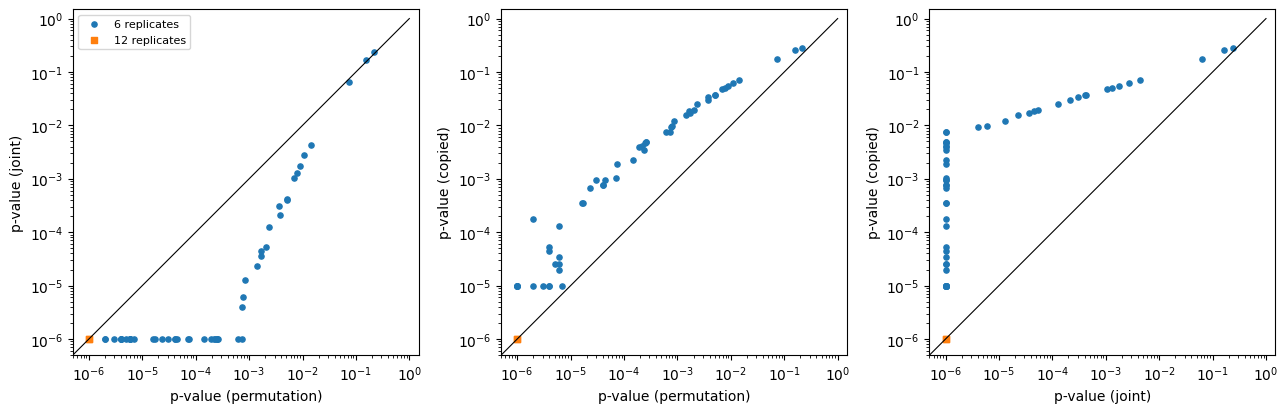

In [4]:
p = pd.DataFrame({null: maps[null]["p_value"] for null in nulls})
p["replicates"] = n_replicates

pairs = [("permutation", "joint"), ("permutation", "copied"), ("joint", "copied")]
lo = p[nulls].min().min() / 2
fig, axes = plt.subplots(1, 3, figsize=(13, 4.6))
for ax, (x, y) in zip(axes, pairs):
    for k, marker in zip(sorted(p["replicates"].unique()), ["o", "s", "^"]):
        sub = p[p["replicates"] == k]
        ax.scatter(sub[x], sub[y], s=14, marker=marker, label=f"{k} replicates")
    ax.plot([lo, 1], [lo, 1], color="black", linewidth=0.8)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(lo, 1.5)
    ax.set_ylim(lo, 1.5)
    ax.set_aspect("equal")
    ax.set_xlabel(f"p-value ({x})")
    ax.set_ylabel(f"p-value ({y})")
axes[0].legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

In [5]:
# compounds whose calls differ between nulls
calls = pd.DataFrame({null: maps[null]["below_corrected_p"] for null in nulls})
differ = calls[calls.nunique(axis=1) > 1]
mean_ap = maps["permutation"]["mean_average_precision"]
p.loc[differ.index].join(mean_ap).sort_values("mean_average_precision")

,permutation,joint,copied,replicates,mean_average_precision
Metadata_broad_sample,,,,,
BRD-K71035033-001-07-1,0.014379,0.004373,0.070001,6,0.451365
BRD-K70557564-305-03-6,0.010795,0.002774,0.061132,6,0.464530
BRD-K72222507-003-16-8,0.008898,0.001747,0.053908,6,0.477479
BRD-K68232413-001-01-2,0.007840,0.001304,0.050013,6,0.485876
BRD-K68132782-003-13-8,0.006919,0.001050,0.047718,6,0.491155


Reading the scatter plots:

- **Weak compounds** (p > 0.05) get similar p-values from all three nulls.
- **Joint vs permutation.** For stronger compounds the joint p-values are smaller, and many reach the floor of $1/(null\_size + 1) = 10^{-6}$ (no draw reached the observed mAP) while the permutation p-values of the same compounds range up to about $10^{-3}$. The joint null samples each similarity independently, so it narrows quickly with replicates. The permutation null draws relabellings of the observed profiles: the replicates share the same DMSO references, and its identity assignment contributes $1/\binom{30}{6} = 1.7 \cdot 10^{-6}$ to the exact tail probability; a finite Monte Carlo estimate can be smaller (see [Null size](./null_size.ipynb)).
- **Copied vs the others.** The copied p-values are larger for every compound with 6 replicates, and the strongest compounds stop at about $10^{-5}$. All 6 replicates have the same pair counts, so they share one AP draw and the group's null is a single AP null of 5 positives among 29 profiles; it does not narrow with replicates, and its exact perfect-retrieval probability is $1/\binom{29}{5} = 8.4 \cdot 10^{-6}$; the finite-sample plus-one p-value still has floor $1/(null\_size + 1)$.
- The 2 compounds with 12 replicates are at the $10^{-6}$ floor under all three nulls.
- **Calls.** The 5 compounds whose calls differ (table above, mAP 0.45 to 0.49) are active under the permutation and joint nulls and not under the copied null.

## Negative control: DMSO pseudo-groups

To see how each null is calibrated, we need groups that truly are exchangeable with their references. We draw them from the DMSO controls alone: in each split, two disjoint pseudo-groups of 6 of the 24 DMSO profiles take the place of compounds, and the remaining 12 DMSO profiles are their references, with the same pair rules as above. A calibrated null gives p < 0.05 for about 5% of pseudo-groups. Each pseudo-group's permutation null has $\binom{18}{6} = 18{,}564$ distinct relabellings (6 members and 12 references), so $10^5$ draws per test are plenty here. We use 50 random splits (100 pseudo-group tests) and report the pooled share with its exact binomial 95% CI. The corrected p-values are corrected within each split, over its 2 pseudo-groups.

One assumption remains: DMSO wells share plate positions, so position effects could still make them less than exchangeable with each other.

In [6]:
n_splits, n_groups, group_size = 50, 2, 6
control_null_size = 100_000
dmso = df[df["Metadata_broad_sample"] == "DMSO"].reset_index(drop=True)
rows = []
for split in range(n_splits):
    rng = np.random.default_rng(split)
    order = rng.permutation(len(dmso))
    labels = np.full(len(dmso), "DMSO", dtype=object)
    for k in range(n_groups):
        labels[order[k * group_size : (k + 1) * group_size]] = f"pseudo_{k}"
    pseudo = dmso.assign(Metadata_broad_sample=labels)
    pseudo_ap = compute_aps(pseudo)
    for null in nulls:
        result, _ = run_null(pseudo_ap, null, control_null_size)
        rows.append(
            result[["p_value", "corrected_p_value"]].assign(split=split, null=null)
        )
pseudo_p = pd.concat(rows, ignore_index=True)


def share(x):
    """Return the pooled share of ``x`` with its exact binomial 95% CI."""
    ci = binomtest(int(x.sum()), len(x)).proportion_ci()
    return f"{100 * x.mean():.1f}% [{100 * ci.low:.1f}, {100 * ci.high:.1f}]"


pseudo_p["p < 0.05"] = pseudo_p["p_value"] < 0.05
pseudo_p["corrected p < 0.05"] = pseudo_p["corrected_p_value"] < 0.05
by_null = pseudo_p.groupby("null", sort=False)
calibration = by_null[["p < 0.05", "corrected p < 0.05"]].agg(share)
calibration = calibration.add_suffix(" (95% CI)")
calibration.insert(0, "tests", by_null.size())
calibration

,tests,p < 0.05 (95% CI),corrected p < 0.05 (95% CI)
null,,,
permutation,100,"5.0% [1.6, 11.3]","4.0% [1.1, 9.9]"
joint,100,"5.0% [1.6, 11.3]","5.0% [1.6, 11.3]"
copied,100,"1.0% [0.0, 5.4]","0.0% [0.0, 3.6]"


With 100 pseudo-group tests, the permutation and joint nulls each give p < 0.05 for 5% of pseudo-groups, as a calibrated null should, and the copied null gives 1%, in line with its wider null. The intervals are wide, and wider in truth than shown: they treat the 100 tests as independent, but the two pseudo-groups of a split share their references, and every split draws from the same 24 DMSO profiles. This control therefore cannot separate the three nulls, and with 6 DMSO replicates per group it does not probe the case the README warns about, too small joint p-values for groups of many replicates on real data.

## Which null to use

- Use the default `"permutation"` for the declared within-pool exchangeability hypothesis. Preserve the attached pair handle, original index and row identities; filter whole groups only. Saved results need the original handle or AP recomputation. The sampled p-value has floor $1/(null\_size + 1)$.
- Use `"joint"` when its independent-pair model is appropriate, including external positives. Multi-member groups require actual positive pairs; singletons may use counts alone. There is no copied fallback. It can give too small p-values for groups of many replicates on real data.
- Use `"copied"` explicitly when its shared-AP-draw model is appropriate. It is also available for multilabel APs, alongside their component-based permutation model, but is not a legacy-reproduction mode. Neither optional model is generally calibrated for real-profile dependence.

The README's [mAP null distributions](https://github.com/cytomining/copairs#map-null-distributions) section lists each null's requirements and limits.